In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('dataset/cars_data.csv')

In [3]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   object 
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   object 
 5   Transmission     1000 non-null   object 
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 62.6+ KB


In [5]:
df.shape

(1000, 8)

In [6]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,1000.000000,1000.000000,980.000000,1000.000000,1000.000000
mean,2016.300000,104551.675000,2.494592,3.062000,8473.646000
std,4.056162,56197.795061,0.865230,1.404325,6292.910864
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4069.500000
50%,2016.000000,105298.000000,2.500000,3.000000,6439.000000
75%,2020.000000,155468.250000,3.225000,4.000000,10905.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [7]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

Brand               0
Year                0
Mileage             0
Engine_Size        20
Fuel_Type           0
Transmission        0
Previous_Owners     0
Price               0
dtype: int64

In [10]:
impute = SimpleImputer(strategy='median')

df[['Engine_Size']] = impute.fit_transform(df[['Engine_Size']])

In [11]:
df.isnull().sum()

Brand              0
Year               0
Mileage            0
Engine_Size        0
Fuel_Type          0
Transmission       0
Previous_Owners    0
Price              0
dtype: int64

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Mileage', y='Price')
plt.title('Price vs Mileage')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Year', y='Price')
plt.title('Price vs Year')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Brand', y='Price')
plt.xticks(rotation=45)
plt.title('Price vs Brand')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Fuel_Type', y='Price')
plt.title('Price vs Fuel_Type')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [17]:
X = df.drop('Price', axis=1)
y = df['Price']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
cat_cols = ['Brand', 'Fuel_Type', 'Transmission']

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

In [20]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
!python -m pip install xgboost catboost lightgbm


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
    AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVR(kernel='linear', C=100, gamma=1),
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [24]:
results = []
all_preds = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    all_preds[name] = y_pred

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2 Score': r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,LightGBM,1495.859362,6.417989e+06,2533.375073,0.844561
1,HistGradientBoosting,1513.222667,6.505369e+06,2550.562436,0.842445
2,CatBoost,1415.741209,6.791655e+06,2606.080347,0.835511
3,GradientBoosting,1684.644297,7.278620e+06,2697.891693,0.823717
4,ExtraTrees,1784.062350,7.730769e+06,2780.426068,0.812767
5,XGBoost,1676.648071,8.116238e+06,2848.901192,0.803431
6,Linear Regression,1970.322723,9.678474e+06,3111.024621,0.765595
7,Lasso,1970.526566,9.683120e+06,3111.771243,0.765482
8,Ridge,1970.470508,9.688384e+06,3112.616896,0.765355
9,Random Forest,2101.787102,1.131276e+07,3363.444540,0.726013


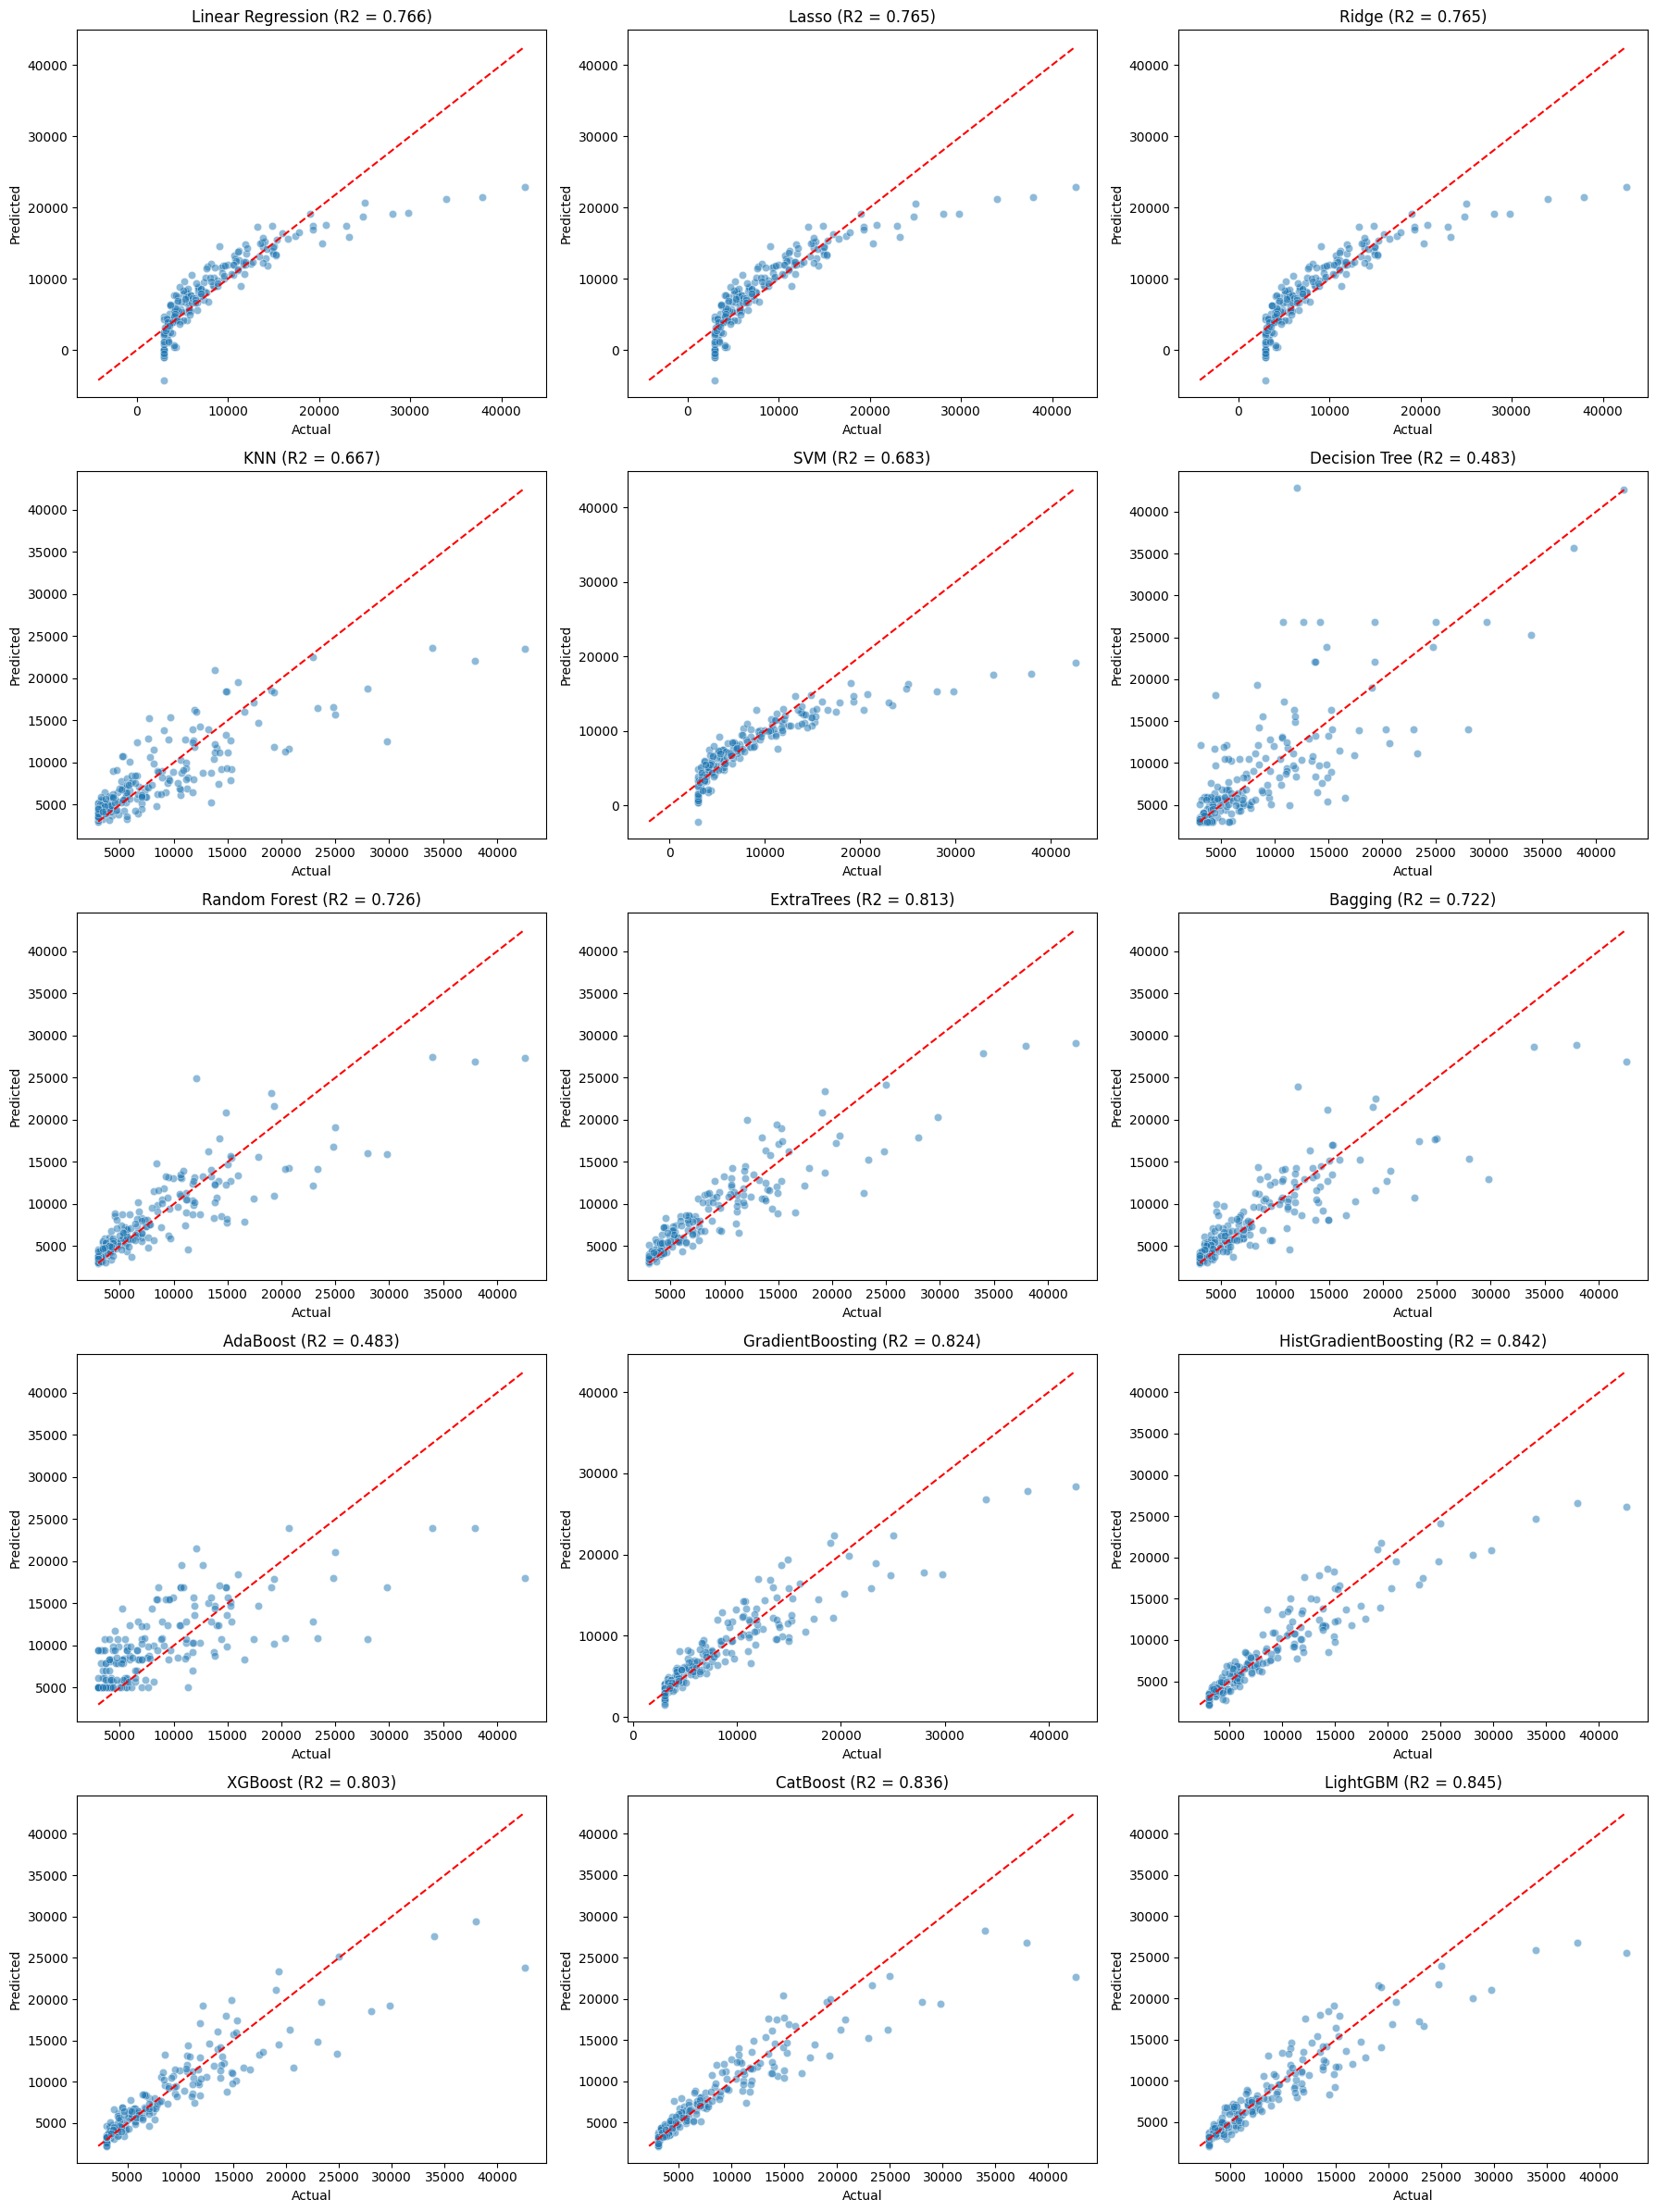

In [25]:
fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_preds.items()):
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=axes[i])
    low = min(np.min(y_test), np.min(y_pred))
    high = max(np.max(y_test), np.max(y_pred))
    axes[i].plot([low, high], [low, high], color='red', linestyle='--')
    axes[i].set_title(f"{name} (R2 = {r2_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Actual')
    axes[i].set_ylabel('Predicted')

plt.tight_layout()
plt.show()

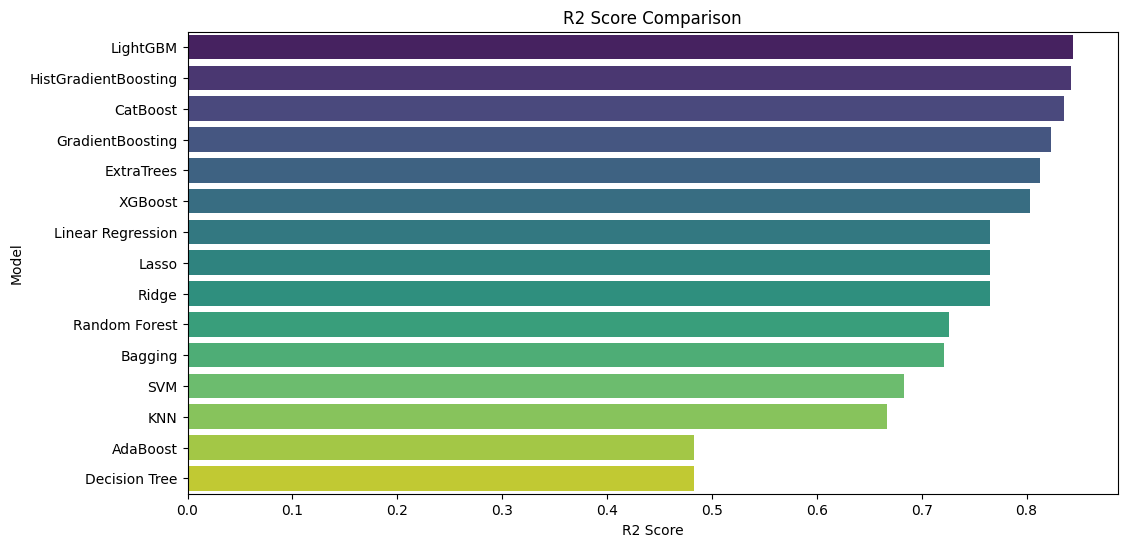

In [26]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x='R2 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('R2 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='r2', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV R2': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV R2', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Linear Regression": {},
    "Lasso": {"alpha": [0.01, 0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10, 100]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [1, 10, 100]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
base_model = clone(models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'R2': r2_score(y_test, p)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
y_pred = best_model.predict(X_test_scaled)
residuals = np.array(y_test) - y_pred

print('MAE :', mean_absolute_error(y_test, y_pred))
print('MSE :', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2  :', r2_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.5)
low, high = min(np.min(y_test), np.min(y_pred)), max(np.max(y_test), np.max(y_pred))
axes[0].plot([low, high], [low, high], color='red', linestyle='--')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals Plot')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
avg_actual = np.mean(np.abs(y_test))

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- R2 = {r2:.3f}: the model explains about {r2*100:.1f}% of the variation in the target.")
print(f"- MAE = {mae:,.2f}: on average the prediction is off by this amount ({mae/avg_actual*100:.1f}% of the average actual value).")
if rmse > 1.5 * mae:
    print(f"- RMSE ({rmse:,.2f}) is much bigger than MAE, so there are some large errors (outliers) the model misses.")
else:
    print(f"- RMSE ({rmse:,.2f}) is close to MAE, so the errors are fairly even with no big outliers.")
print(f"- Mean residual = {residuals.mean():,.2f}: close to 0 means the model does not systematically over- or under-predict.")
print(f"- Tuning changed R2 from {rows[0]['R2']:.3f} to {rows[1]['R2']:.3f}.")

## Save the model for the Streamlit app
This creates `model.joblib`. Put it next to `app.py`.

In [ ]:
import joblib

# original columns (before get_dummies) -> used to build the form in the app
raw = df.drop(columns=['Price'])
inputs = {}
for col in raw.columns:
    if col in cat_cols or raw[col].nunique() <= 2:
        inputs[col] = ('choice', sorted(raw[col].unique().tolist()))
    elif pd.api.types.is_integer_dtype(raw[col]):
        inputs[col] = ('number', int(raw[col].min()), int(raw[col].max()), int(raw[col].median()))
    else:
        inputs[col] = ('number', float(raw[col].min()), float(raw[col].max()), float(raw[col].median()))

joblib.dump({'model': best_model,
             'scaler': scaler,
             'inputs': inputs,
             'cat_cols': cat_cols,
             'dummy_columns': list(X_train.columns)}, 'model.joblib', compress=3)